# Rekomendasi Lokasi Coffee Shop di Kota Bandung
## Baseline: fitur spasial KNN + KDE → perbandingan K-Means vs HDBSCAN

**Alur notebook**
1. Konfigurasi
2. Ekstraksi data dari file OSM `.pbf` (BBBike)
3. Preprocessing: kategorisasi, filter kompetitor, deduplikasi, klip & proyeksi
4. Grid kandidat lokasi (H3 resolusi 9)
5. Feature engineering: **KNN** (jarak tetangga) dan **KDE** (kepadatan, bandwidth tetap & adaptif)
6. Scaling & cek korelasi
7. Clustering: **K-Means vs HDBSCAN** (+ GMM sebagai pembanding tambahan)
8. Evaluasi: metrik internal, stabilitas, koherensi spasial, validasi hold-out kompetitor
9. Profil cluster & penentuan cluster rekomendasi
10. Peta hasil
11. Fungsi rekomendasi: input 1 titik → output area rekomendasi

**Kebutuhan:** `pip install osmium geopandas shapely pyproj h3 scikit-learn matplotlib folium pandas numpy scipy`

Catatan: semua angka di notebook ini dihasilkan dari snapshot OSM yang diekstrak dari BBBike. Karena OSM belum mencatat semua coffee shop Bandung, hasilnya adalah **baseline metodologi**, bukan rekomendasi bisnis final.

## 1. Konfigurasi
Semua parameter penting dikumpulkan di sini supaya mudah diuji sensitivitasnya.

In [1]:
pip install osmium geopandas shapely pyproj h3 scikit-learn matplotlib folium pandas numpy scipy


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings, time, re
warnings.filterwarnings("ignore")
import os; os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np, pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Polygon, Point
import h3, osmium
from scipy.spatial import cKDTree
from sklearn.neighbors import KernelDensity, BallTree
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, roc_auc_score)
import matplotlib.pyplot as plt
from IPython.display import display

PBF_PATH      = "bandung.pbf"   # ganti dengan path file BBBike-mu
CRS_METER     = 32748               # UTM zona 48S, satuan meter
H3_RES        = 9                   # ~0,1 km² per sel
BUFFER_POI_M  = 3000                # POI di luar batas kota tetap dipakai (hindari efek tepi)
BANDWIDTH_M   = 500                 # bandwidth KDE tetap (≈ jarak jalan kaki 5-7 menit)
K_PILOT       = 10                  # k untuk bandwidth adaptif (KDE berbasis KNN)
H_MIN, H_MAX  = 150, 2000           # batas bandwidth adaptif (meter)
SEED          = 42
TERMASUK_POINT_COFFEE = True        # Point Coffee (di Indomaret) dihitung kompetitor?

# Merek/nama yang tercatat amenity=cafe tetapi BUKAN coffee shop (bisa kamu tambah/kurangi)
BUKAN_KOPI = [r"chatime", r"mixue", r"gotcha", r"xing fu tang", r"koi th", r"es teh",
              r"gulu gulu", r"puyo", r"j\.?co", r"dunkin", r"warnet", r"baso", r"spbu",
              r"fruity", r"durian", r"ice cream"]
if not TERMASUK_POINT_COFFEE:
    BUKAN_KOPI.append(r"point coffee")

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
rng = np.random.default_rng(SEED)

## 2. Ekstraksi data dari file `.pbf`
File `.pbf` dibaca sekali jalan dengan `pyosmium`:
- **node** → titik POI langsung
- **area** (way tertutup / multipolygon) → diambil titik tengahnya (centroid). Ini mencakup POI yang digambar sebagai bangunan, semua bangunan (untuk proxy kepadatan permukiman), dan batas administrasi.

In [3]:
def kategori(t):
    """Petakan tag OSM → kategori analisis. Urutan if = prioritas."""
    a, s = t.get("amenity"), t.get("shop")
    c = t.get("cuisine", "").lower()
    if a == "cafe" or s == "coffee" or ("coffee" in c and a in ("restaurant", "fast_food")):
        return "kompetitor"
    if a in ("university", "college"):                        return "kampus"
    if a == "school":                                         return "sekolah"
    if "office" in t or a == "coworking_space":               return "kantor"
    if s in ("mall", "department_store", "supermarket"):      return "belanja"
    if (t.get("railway") == "station" or t.get("public_transport") == "station"
            or a == "bus_station"):                           return "transportasi"
    if t.get("tourism") in ("hotel", "guest_house", "hostel", "attraction", "museum"):
        return "wisata_hotel"
    if a in ("hospital", "clinic"):                           return "kesehatan"
    if a == "bank":                                           return "bank"
    if a in ("restaurant", "fast_food", "food_court"):        return "kuliner"
    return None

wkb = osmium.geom.WKBFactory()

# --- Langkah 1: cari relation batas administrasi (Kota Bandung = admin_level 5, kecamatan = 6)
class RelasiBatas(osmium.SimpleHandler):
    def __init__(self):
        super().__init__(); self.rel = []
    def relation(self, r):
        t = dict(r.tags)
        if t.get("boundary") == "administrative" and t.get("admin_level") in ("5", "6"):
            self.rel.append(dict(name=t.get("name"), admin_level=t["admin_level"],
                                 ways=[m.ref for m in r.members if m.type == "w" and m.role != "subarea"]))

rb = RelasiBatas(); rb.apply_file(PBF_PATH)
WAY_BATAS = {w for r in rb.rel for w in r["ways"]}

# --- Langkah 2: satu pass utama untuk POI, bangunan, dan garis batas
class Ekstraktor(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.poi, self.bangunan_wkb, self.garis_batas = [], [], {}

    def node(self, n):
        if len(n.tags) == 0:
            return
        t = dict(n.tags); k = kategori(t)
        if k:
            self.poi.append(dict(osm_id=f"n{n.id}", kategori=k, name=t.get("name", ""),
                                 lon=n.location.lon, lat=n.location.lat, wkb=None))

    def way(self, w):
        if w.id in WAY_BATAS:
            try:
                self.garis_batas[w.id] = shapely.LineString([(n.lon, n.lat) for n in w.nodes])
            except Exception:
                pass

    def area(self, a):
        t = dict(a.tags)
        if "boundary" in t:
            return
        try:
            k = kategori(t)
            if k:
                self.poi.append(dict(osm_id=f"a{a.id}", kategori=k, name=t.get("name", ""),
                                     lon=None, lat=None, wkb=wkb.create_multipolygon(a)))
            elif "building" in t:
                self.bangunan_wkb.append(wkb.create_multipolygon(a))
        except Exception:
            pass   # geometri rusak/tidak lengkap di tepi ekstrak → lewati

t0 = time.time()
ex = Ekstraktor()
ex.apply_file(PBF_PATH, locations=True)
print(f"Selesai {time.time()-t0:.0f} detik | POI: {len(ex.poi):,} | bangunan: {len(ex.bangunan_wkb):,} | relation batas: {len(rb.rel)}")

Selesai 11 detik | POI: 4,560 | bangunan: 574,072 | relation batas: 38


### Merakit polygon batas administrasi
Pada ekstrak BBBike, sebagian garis batas Kota Bandung (sisi utara di Cidadap/Coblong/Sukasari dan sisi timur di Cibiru) **terpotong**, sehingga polygon tidak bisa dibentuk otomatis.
Fungsi `rakit_polygon` menyambung ujung-ujung garis yang terputus dengan garis lurus, lalu membentuk polygon. Panjang total sambungan dilaporkan; batas yang disambung ditandai `perkiraan=True`.
Kalau kamu punya file batas resmi (mis. dari BIG / geoBoundaries / BPS), lebih baik pakai itu: isi `BATAS_FILE` di bawah.

In [4]:
from shapely.ops import linemerge, polygonize, unary_union
BATAS_FILE = None   # contoh: "batas_kota_bandung.geojson" (kolom: name, admin_level)

def rakit_polygon(lines):
    merged = shapely.line_merge(unary_union(lines))
    chains = [list(c.coords) for c in getattr(merged, "geoms", [merged])]
    gap = 0.0
    while True:
        terbuka = [i for i, c in enumerate(chains) if c[0] != c[-1]]
        if not terbuka:
            break
        i = terbuka[0]; ujung = np.array(chains[i][-1])
        # cari awal/akhir chain terbuka lain (atau awal dirinya sendiri) yang paling dekat
        kand = [(np.linalg.norm(ujung - np.array(chains[j][0])), j, False) for j in terbuka] + \
               [(np.linalg.norm(ujung - np.array(chains[j][-1])), j, True) for j in terbuka if j != i]
        d, j, balik = min(kand)
        gap += d
        if j == i:
            chains[i] = chains[i] + [chains[i][0]]
        else:
            nxt = chains[j][::-1] if balik else chains[j]
            chains[i] = chains[i] + nxt
            chains.pop(j)
    polys = list(polygonize([shapely.LineString(c) for c in chains]))
    return unary_union(polys), gap

if BATAS_FILE:
    batas = gpd.read_file(BATAS_FILE).to_crs(4326)
else:
    rows = []
    for r in rb.rel:
        lines = [ex.garis_batas[w] for w in r["ways"] if w in ex.garis_batas]
        if not lines:
            continue
        geom, gap = rakit_polygon(lines)
        if geom.is_empty:
            continue
        gap_m = gap * 111_000      # derajat → meter (perkiraan kasar)
        rows.append(dict(name=r["name"], admin_level=r["admin_level"],
                         way_hilang=len(r["ways"]) - len(lines), sambungan_m=round(gap_m),
                         perkiraan=gap_m > 1, geometry=geom))
    batas = gpd.GeoDataFrame(rows, crs=4326)

kota = batas[(batas.admin_level == "5") & (batas.name == "Kota Bandung")]
kota_union = kota.geometry.union_all()
kecamatan = batas[(batas.admin_level == "6") &
                  batas.geometry.representative_point().within(kota_union)].copy()
print(f"Kota Bandung: {kota.to_crs(CRS_METER).area.sum()/1e6:.1f} km² (luas resmi ±167 km²) | kecamatan: {len(kecamatan)}")
display(batas[batas.perkiraan][["name", "admin_level", "way_hilang", "sambungan_m"]] if "perkiraan" in batas else None)

Kota Bandung: 161.6 km² (luas resmi ±167 km²) | kecamatan: 30


,name,admin_level,way_hilang,sambungan_m
0,Kota Bandung,5,10,5014
1,Coblong,6,2,421
16,Cibiru,6,2,832
17,Cidadap,6,5,3201
18,Sukasari,6,5,1055
31,Sumedang,5,43,7040
32,Kabupaten Bandung,5,66,50838
34,Cileunyi,6,10,6159
35,Bojongsoang,6,28,8502
36,Dayeuhkolot,6,9,4491


In [5]:
# POI → GeoDataFrame (titik). Area → centroid.
poi = pd.DataFrame(ex.poi)
geom = [shapely.from_wkb(r.wkb).centroid if isinstance(r.wkb, str) else Point(r.lon, r.lat)
        for r in poi.itertuples()]
poi = gpd.GeoDataFrame(poi.drop(columns=["wkb", "lon", "lat"]), geometry=geom, crs=4326)
bangunan = gpd.GeoDataFrame(geometry=shapely.centroid(shapely.from_wkb(ex.bangunan_wkb)), crs=4326)
poi.kategori.value_counts().rename("jumlah (sebelum dibersihkan)").to_frame()

,jumlah (sebelum dibersihkan)
kategori,
kuliner,1342
kantor,669
sekolah,665
kompetitor,532
wisata_hotel,416
bank,352
belanja,207
kesehatan,195
kampus,127


## 3. Preprocessing
1. **Filter kompetitor**: buang nama yang bukan coffee shop (daftar `BUKAN_KOPI`).
2. **Deduplikasi**: satu tempat bisa tercatat 2× (node + bangunan). Kompetitor dengan nama sama dalam radius 30 m dianggap duplikat.
3. **Proyeksi** ke UTM 48S (meter) dan **klip** ke batas Kota Bandung + buffer 3 km.

In [6]:
poi = poi.to_crs(CRS_METER); bangunan = bangunan.to_crs(CRS_METER)
kota_m = kota.to_crs(CRS_METER); kecamatan_m = kecamatan.to_crs(CRS_METER)
area_studi = kota_m.geometry.union_all()
area_buffer = area_studi.buffer(BUFFER_POI_M)

# 1) filter nama non-kopi
pola = re.compile("|".join(BUKAN_KOPI), flags=re.I)
is_komp = poi.kategori == "kompetitor"
dibuang = poi[is_komp & poi.name.str.contains(pola)]
poi = poi.drop(dibuang.index)
print(f"Kompetitor dibuang karena bukan coffee shop: {len(dibuang)}")
print(dibuang.name.value_counts().head(10).to_string())

# 2) deduplikasi kompetitor (nama sama, jarak < 30 m)
komp = poi[poi.kategori == "kompetitor"].copy()
xy = np.c_[komp.geometry.x, komp.geometry.y]
pairs = cKDTree(xy).query_pairs(r=30)
nama = komp.name.str.lower().str.strip().values
dup = {max(i, j) for i, j in pairs if nama[i] == nama[j]}
poi = poi.drop(komp.index[list(dup)])
print(f"Duplikat kompetitor dihapus: {len(dup)}")

# 3) klip
poi = poi[poi.within(area_buffer)].copy()
poi["di_kota"] = poi.within(area_studi)
bangunan = bangunan[bangunan.within(area_buffer)]
print(f"Luas Kota Bandung: {area_studi.area/1e6:.1f} km² | bangunan dalam buffer: {len(bangunan):,}")

ringkas = poi.groupby("kategori").agg(total_dalam_buffer=("di_kota", "size"),
                                       di_dalam_kota=("di_kota", "sum"))
ringkas.sort_values("total_dalam_buffer", ascending=False)

Kompetitor dibuang karena bukan coffee shop: 64
name
Chatime                       14
J.Co                          13
Dunkin'                        8
Mixue                          8
Gulu Gulu                      2
Puyo                           2
SPBU Dago                      1
Cafe Pohon Durian Bandung      1
Gotcha Ice Cream               1
Jifast The Power Of Durian     1
Duplikat kompetitor dihapus: 11
Luas Kota Bandung: 161.6 km² | bangunan dalam buffer: 552,924


,total_dalam_buffer,di_dalam_kota
kategori,,
kuliner,1337,1275
kantor,666,635
sekolah,652,569
kompetitor,452,426
wisata_hotel,416,405
bank,351,345
belanja,205,186
kesehatan,190,158
kampus,124,108


## 4. Grid kandidat lokasi (H3)
Setiap sel heksagon H3 resolusi 9 (~0,1 km²) adalah satu "kandidat lokasi". Heksagon dipilih karena jarak ke semua tetangganya seragam.

In [7]:
kota_wgs = kota.geometry.union_all()
cells = sorted(h3.geo_to_cells(kota_wgs.__geo_interface__, res=H3_RES))
grid = gpd.GeoDataFrame({"h3": cells},
        geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells],
        crs=4326).to_crs(CRS_METER)
cen = grid.geometry.centroid
grid["x"], grid["y"] = cen.x.values, cen.y.values
G = np.c_[grid.x, grid.y]
grid = gpd.sjoin(grid, kecamatan_m[["name", "geometry"]].rename(columns={"name": "kecamatan"}),
                 how="left", predicate="intersects").drop_duplicates("h3").drop(columns="index_right")
grid = grid.reset_index(drop=True)
print(f"Jumlah sel: {len(grid):,} | rata-rata luas sel: {grid.area.mean()/1e6:.3f} km²")

Jumlah sel: 1,542 | rata-rata luas sel: 0.104 km²


## 5. Feature engineering

### 5a. Fitur KNN (jarak ke tetangga terdekat)
Untuk setiap sel dihitung jarak dari titik tengah sel ke POI terdekat. Untuk kompetitor dipakai jarak ke tetangga ke-1 dan rata-rata 3 tetangga terdekat.

In [8]:
def xy_of(kat):
    g = poi[poi.kategori.isin([kat] if isinstance(kat, str) else kat)].geometry
    return np.c_[g.x, g.y]

def jarak_knn(target_xy, sumber_xy, k=1):
    d, _ = cKDTree(sumber_xy).query(target_xy, k=k)
    return d if k == 1 else d.mean(axis=1)

KOMP = xy_of("kompetitor")
DEMAND_KAT = ["kampus", "sekolah", "kantor", "belanja", "transportasi",
              "wisata_hotel", "kesehatan", "bank", "kuliner"]
DEMAND = xy_of(DEMAND_KAT)

grid["d_komp1"]       = jarak_knn(G, KOMP, 1)
grid["d_komp3"]       = jarak_knn(G, KOMP, 3)
grid["d_kampus"]      = jarak_knn(G, xy_of("kampus"))
grid["d_kantor"]      = jarak_knn(G, xy_of("kantor"))
grid["d_belanja"]     = jarak_knn(G, xy_of("belanja"))
grid["d_transportasi"] = jarak_knn(G, xy_of("transportasi"))
grid.filter(like="d_").describe().round(0)

,d_komp1,d_komp3,d_kampus,d_kantor,d_belanja,d_transportasi
count,1542.0,1542.0,1542.0,1542.0,1542.0,1542.0
mean,770.0,970.0,1207.0,506.0,729.0,1109.0
std,617.0,652.0,899.0,402.0,542.0,653.0
min,8.0,25.0,14.0,3.0,17.0,17.0
25%,312.0,458.0,508.0,219.0,344.0,635.0
50%,602.0,837.0,934.0,394.0,588.0,1005.0
75%,1049.0,1338.0,1731.0,674.0,972.0,1471.0
max,3579.0,3714.0,4167.0,2333.0,3547.0,3872.0


### 5b. Fitur KDE (kepadatan)
Hasil KDE diubah menjadi **intensitas = jumlah titik per km²** supaya mudah dibaca.

**Pemilihan bandwidth.** Sebagai pembanding, bandwidth dari aturan Scott dan dari cross-validation (log-likelihood) dihitung untuk data kompetitor. Notebook ini memakai 500 m karena alasan substantif (jangkauan jalan kaki); hasil CV dilaporkan sebagai bahan diskusi/sensitivitas.

In [9]:
def scott_bw(xy):
    n = len(xy); return float(np.mean(xy.std(axis=0)) * n ** (-1/6))

cv = GridSearchCV(KernelDensity(kernel="gaussian"),
                  {"bandwidth": [150, 250, 350, 500, 750, 1000, 1500]}, cv=5).fit(KOMP)
print(f"Bandwidth kompetitor  | Scott: {scott_bw(KOMP):.0f} m | CV terbaik: {cv.best_params_['bandwidth']} m | dipakai: {BANDWIDTH_M} m")
print(f"Bandwidth permintaan  | Scott: {scott_bw(DEMAND):.0f} m")

def kde_tetap(src, target=G, h=BANDWIDTH_M):
    kd = KernelDensity(bandwidth=h, kernel="gaussian").fit(src)
    return len(src) * np.exp(kd.score_samples(target)) * 1e6     # titik per km²

grid["kde_permintaan"] = kde_tetap(DEMAND)
grid["kde_kampus"]     = kde_tetap(xy_of("kampus"))
grid["kde_kantor"]     = kde_tetap(xy_of("kantor"))
grid["kde_kompetitor"] = kde_tetap(KOMP)
grid["kde_bangunan"]   = kde_tetap(np.c_[bangunan.geometry.x, bangunan.geometry.y])

Bandwidth kompetitor  | Scott: 1094 m | CV terbaik: 750 m | dipakai: 500 m
Bandwidth permintaan  | Scott: 818 m


### 5c. KDE dengan bandwidth adaptif (gabungan KNN + KDE)
Bandwidth setiap titik $h_i$ = jarak titik $i$ ke tetangga ke-$k$ (k = `K_PILOT`). Di pusat kota yang padat $h_i$ kecil (detail tajam), di pinggiran $h_i$ besar (halus).

$$\hat f(x) = \frac{1}{n}\sum_{i=1}^{n} \frac{1}{2\pi h_i^2}\exp\left(-\frac{\lVert x-x_i\rVert^2}{2h_i^2}\right)$$

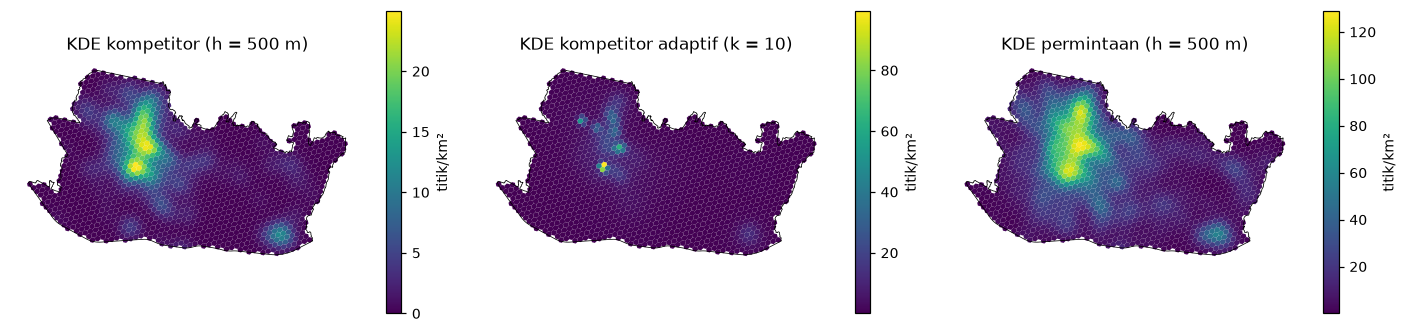

In [10]:
def kde_adaptif(src, target=G, k=K_PILOT, hmin=H_MIN, hmax=H_MAX):
    d, _ = cKDTree(src).query(src, k=k + 1)          # +1 karena tetangga pertama = diri sendiri
    h = np.clip(d[:, -1], hmin, hmax)
    out = np.zeros(len(target))
    for s in range(0, len(src), 2000):               # dipecah agar hemat memori
        diff = target[:, None, :] - src[None, s:s+2000, :]
        d2 = (diff ** 2).sum(-1); hh = h[s:s+2000]
        out += (np.exp(-d2 / (2 * hh**2)) / (2 * np.pi * hh**2)).sum(1)
    return out * 1e6                                  # titik per km²

grid["kdea_permintaan"] = kde_adaptif(DEMAND)
grid["kdea_kompetitor"] = kde_adaptif(KOMP)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, col, judul in zip(ax, ["kde_kompetitor", "kdea_kompetitor", "kde_permintaan"],
                         ["KDE kompetitor (h = 500 m)", f"KDE kompetitor adaptif (k = {K_PILOT})", "KDE permintaan (h = 500 m)"]):
    grid.plot(column=col, cmap="viridis", ax=a, legend=True, legend_kwds={"shrink": .7, "label": "titik/km²"})
    kota_m.boundary.plot(ax=a, color="k", lw=.5); a.set_title(judul); a.set_axis_off()
plt.tight_layout(); plt.show()

## 6. Set fitur, transformasi & korelasi
Empat set fitur dibuat untuk **ablation study** (membuktikan bahwa penggabungan KNN + KDE memang membantu):

| Set | Isi |
|---|---|
| `KNN` | 6 fitur jarak |
| `KDE` | 5 fitur kepadatan (bandwidth tetap) |
| `KNN+KDE` | gabungan 11 fitur — **set utama** |
| `KNN+KDE_adaptif` | 6 fitur jarak + KDE adaptif untuk permintaan & kompetitor + 3 KDE tetap |

Semua fitur di-`log1p` (distribusinya sangat menceng) lalu distandarkan (`StandardScaler`).

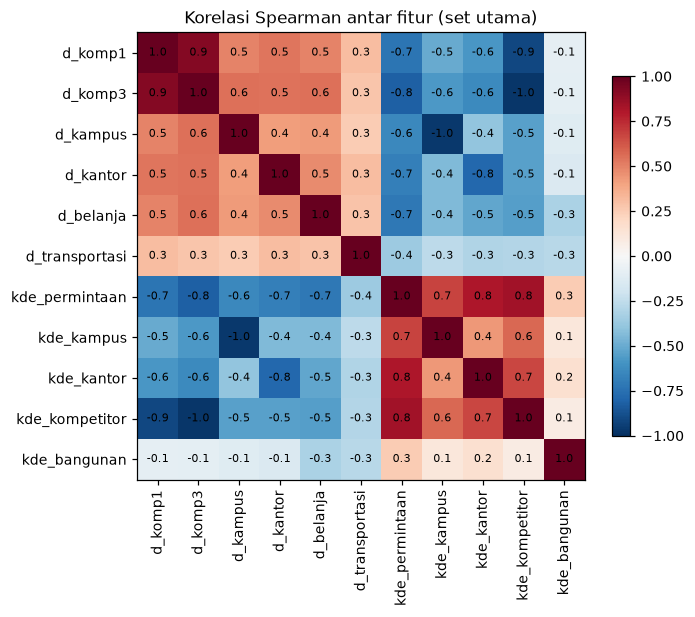

Pasangan |r| > 0,8:
  d_komp1          ~ d_komp3          r = +0.92
  d_komp1          ~ kde_kompetitor   r = -0.91
  d_komp3          ~ kde_permintaan   r = -0.81
  d_komp3          ~ kde_kompetitor   r = -0.97
  d_kampus         ~ kde_kampus       r = -0.96
  kde_permintaan   ~ kde_kantor       r = +0.81
  kde_permintaan   ~ kde_kompetitor   r = +0.84


In [11]:
F_KNN = ["d_komp1", "d_komp3", "d_kampus", "d_kantor", "d_belanja", "d_transportasi"]
F_KDE = ["kde_permintaan", "kde_kampus", "kde_kantor", "kde_kompetitor", "kde_bangunan"]
SETS = {
    "KNN": F_KNN,
    "KDE": F_KDE,
    "KNN+KDE": F_KNN + F_KDE,
    "KNN+KDE_adaptif": F_KNN + ["kdea_permintaan", "kdea_kompetitor", "kde_kampus", "kde_kantor", "kde_bangunan"],
}
UTAMA = "KNN+KDE"

def matriks(cols, df=grid):
    return StandardScaler().fit_transform(np.log1p(df[cols].values))

X = {nama: matriks(cols) for nama, cols in SETS.items()}

corr = pd.DataFrame(np.log1p(grid[SETS[UTAMA]]).corr(method="spearman"))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=.8); ax.set_title("Korelasi Spearman antar fitur (set utama)"); plt.tight_layout(); plt.show()
tinggi = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr) for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > .8]
print("Pasangan |r| > 0,8:")
for a, b, r in tinggi:
    print(f"  {a:16s} ~ {b:16s} r = {r:+.2f}")

**Catatan korelasi.** Beberapa fitur KNN dan KDE sangat berkorelasi (mis. `d_komp3` vs `kde_kompetitor`, `d_kampus` vs `kde_kampus`, |r| > 0,9). Artinya keduanya sebagian besar mengukur hal yang sama: "dekat dengan banyak X" ≈ "kepadatan X tinggi". Konsekuensi untuk penelitian:
- Ini justru alasan **ablation study** (set KNN saja / KDE saja / gabungan) penting: membuktikan apakah penggabungan menambah informasi atau hanya redundansi.
- Alternatif: buang salah satu dari pasangan berkorelasi tinggi, atau pakai PCA sebelum clustering. Coba sebagai uji sensitivitas.

## 7. Clustering

### 7a. Fungsi evaluasi
- **Silhouette** (↑ lebih baik, −1..1), **Davies-Bouldin** (↓), **Calinski-Harabasz** (↑).
- Untuk HDBSCAN, metrik dihitung **hanya pada sel non-noise**, dan **% noise** dilaporkan terpisah supaya perbandingannya adil.
- **Koherensi spasial**: proporsi pasangan sel bertetangga (H3) yang berlabel sama, dibandingkan dengan label yang diacak (z-score). Nilai z besar = cluster membentuk zona yang menyatu di peta.

In [12]:
TETANGGA = []
idx_of = {c: i for i, c in enumerate(grid.h3)}
for i, c in enumerate(grid.h3):
    for nb in h3.grid_ring(c, 1):
        j = idx_of.get(nb)
        if j is not None and j > i:
            TETANGGA.append((i, j))
TETANGGA = np.array(TETANGGA)

def koherensi_spasial(labels, n_perm=199):
    m = (labels[TETANGGA[:, 0]] != -1) & (labels[TETANGGA[:, 1]] != -1)
    P = TETANGGA[m]
    obs = np.mean(labels[P[:, 0]] == labels[P[:, 1]])
    lab = labels.copy(); valid = np.where(lab != -1)[0]; sims = []
    for _ in range(n_perm):
        lab[valid] = rng.permutation(labels[valid])
        sims.append(np.mean(lab[P[:, 0]] == lab[P[:, 1]]))
    return obs, (obs - np.mean(sims)) / np.std(sims)

def evaluasi(Xs, labels):
    m = labels != -1
    k = len(set(labels[m]))
    hasil = dict(n_cluster=k, noise_pct=100 * (1 - m.mean()))
    if k >= 2:
        hasil.update(silhouette=silhouette_score(Xs[m], labels[m]),
                     davies_bouldin=davies_bouldin_score(Xs[m], labels[m]),
                     calinski_harabasz=calinski_harabasz_score(Xs[m], labels[m]))
        hasil["tetangga_sama_label"], hasil["z_spasial"] = koherensi_spasial(labels)
    return hasil

### 7b. K-Means — memilih k
k diuji dari 2 sampai 10. Elbow (inertia) + Silhouette + Davies-Bouldin. Aturan pemilihan: **k dengan silhouette tertinggi pada rentang 3–8** (k = 2 biasanya hanya memisahkan "kota" vs "pinggiran", terlalu kasar untuk rekomendasi).

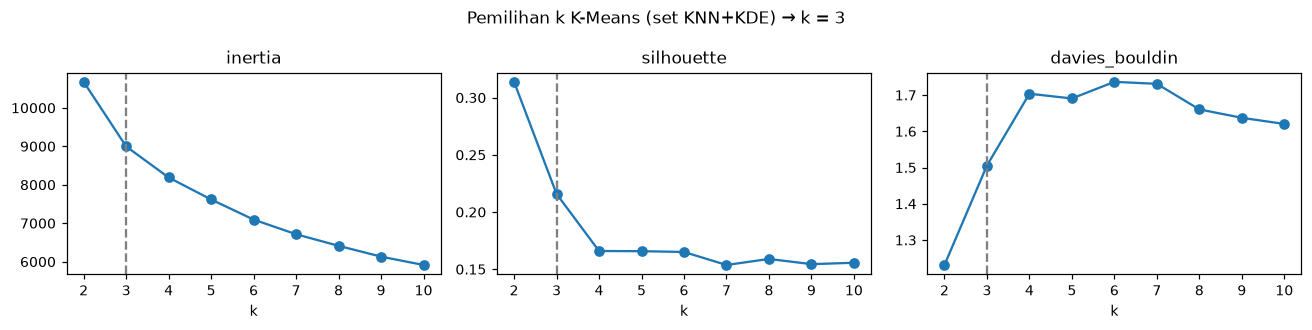

,k,inertia,silhouette,davies_bouldin
0,2,10677.440,0.314,1.231
1,3,8997.492,0.216,1.506
2,4,8190.511,0.166,1.704
3,5,7618.455,0.166,1.691
4,6,7095.863,0.165,1.737
5,7,6715.173,0.154,1.731
6,8,6413.668,0.159,1.661
7,9,6132.903,0.154,1.637
8,10,5915.800,0.156,1.620


In [13]:
def pilih_kmeans(Xs, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=SEED).fit(Xs)
        rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Xs, km.labels_),
                         davies_bouldin=davies_bouldin_score(Xs, km.labels_)))
    tab = pd.DataFrame(rows)
    k_best = int(tab[tab.k.between(3, 8)].sort_values("silhouette", ascending=False).k.iloc[0])
    return k_best, tab

k_utama, tab_k = pilih_kmeans(X[UTAMA])
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, col in zip(ax, ["inertia", "silhouette", "davies_bouldin"]):
    a.plot(tab_k.k, tab_k[col], "o-"); a.axvline(k_utama, ls="--", c="gray"); a.set_title(col); a.set_xlabel("k")
plt.suptitle(f"Pemilihan k K-Means (set {UTAMA}) → k = {k_utama}"); plt.tight_layout(); plt.show()
tab_k.round(3)

### 7c. HDBSCAN — grid search parameter
Parameter yang diuji: `min_cluster_size` (ukuran cluster minimum), `min_samples` (makin besar makin konservatif → makin banyak noise), dan `cluster_selection_method` (`eom` = cluster besar & stabil, `leaf` = cluster kecil-kecil).

Aturan pemilihan bertingkat (dipakai tingkat pertama yang punya kandidat), lalu ambil silhouette (non-noise) tertinggi:
1. noise ≤ 30% dan ≥ 3 cluster
2. noise ≤ 30% dan ≥ 2 cluster
3. noise ≤ 50% dan ≥ 2 cluster
4. noise paling kecil dengan ≥ 2 cluster

Tingkat yang terpakai dicetak, karena itu sendiri informasi penting: kalau HDBSCAN hanya lolos di tingkat 3–4, artinya data tidak punya struktur kepadatan yang jelas.

In [14]:
def pilih_hdbscan(Xs, mcs_list=(10, 15, 25, 40, 60), ms_list=(1, 3, 5, 10, 20), metode=("eom", "leaf"), verbose=False):
    rows = []
    for meth in metode:
        for mcs in mcs_list:
            for ms in ms_list:
                lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=meth, copy=True).fit_predict(Xs)
                m = lab != -1; k = len(set(lab[m]))
                sil = silhouette_score(Xs[m], lab[m]) if k >= 2 else np.nan
                rows.append(dict(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=meth,
                                 n_cluster=k, noise_pct=100 * (1 - m.mean()), silhouette=sil))
    tab = pd.DataFrame(rows)
    tingkat = [(30, 3), (30, 2), (50, 2)]
    for t, (nmax, kmin) in enumerate(tingkat, 1):
        ok = tab[(tab.noise_pct <= nmax) & (tab.n_cluster >= kmin)].dropna()
        if len(ok):
            b = ok.sort_values("silhouette", ascending=False).iloc[0]; break
    else:
        t = 4; b = tab[tab.n_cluster >= 2].sort_values("noise_pct").iloc[0]
    par = dict(min_cluster_size=int(b.min_cluster_size), min_samples=int(b.min_samples),
               cluster_selection_method=b.cluster_selection_method)
    if verbose:
        print(f"Tingkat aturan terpakai: {t} | parameter: {par} | {int(b.n_cluster)} cluster, noise {b.noise_pct:.1f}%")
    return par, tab, t

par_hdb, tab_hdb, _ = pilih_hdbscan(X[UTAMA], verbose=True)
print("Konfigurasi dengan >= 3 cluster dan noise <= 30%:",
      len(tab_hdb[(tab_hdb.n_cluster >= 3) & (tab_hdb.noise_pct <= 30)]), "dari", len(tab_hdb))
tab_hdb.sort_values("silhouette", ascending=False).head(10).round(3)

Tingkat aturan terpakai: 2 | parameter: {'min_cluster_size': 10, 'min_samples': 5, 'cluster_selection_method': 'eom'} | 2 cluster, noise 24.1%
Konfigurasi dengan >= 3 cluster dan noise <= 30%: 0 dari 50


,min_cluster_size,min_samples,cluster_selection_method,n_cluster,noise_pct,silhouette
2,10,5,eom,2,24.125,0.407
7,15,5,eom,2,24.125,0.407
1,10,3,eom,2,19.844,0.380
0,10,1,eom,2,15.370,0.360
5,15,1,eom,2,15.370,0.360
27,10,5,leaf,11,89.235,0.331
32,15,5,leaf,5,92.672,0.330
40,40,1,leaf,4,81.128,0.317
36,25,3,leaf,5,87.808,0.302
41,40,3,leaf,3,85.927,0.287


### 7d. GMM (pembanding tambahan) — memilih jumlah komponen dengan BIC

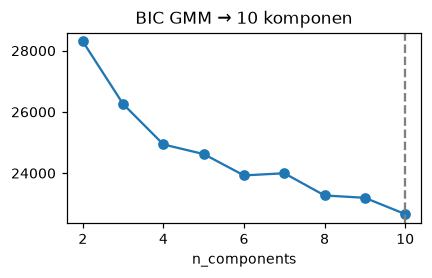

Catatan: BIC terus turun sampai batas atas (10) → tidak ada jumlah komponen optimal yang jelas; GMM cenderung memecah gradasi kontinu menjadi banyak potongan.


In [15]:
bic = [GaussianMixture(n, covariance_type="full", random_state=SEED, n_init=3).fit(X[UTAMA]).bic(X[UTAMA]) for n in range(2, 11)]
n_gmm = int(np.argmin(bic) + 2)
plt.figure(figsize=(4, 2.6)); plt.plot(range(2, 11), bic, "o-"); plt.axvline(n_gmm, ls="--", c="gray")
plt.title(f"BIC GMM → {n_gmm} komponen"); plt.xlabel("n_components"); plt.tight_layout(); plt.show()
if n_gmm == 10:
    print("Catatan: BIC terus turun sampai batas atas (10) → tidak ada jumlah komponen optimal yang jelas; GMM cenderung memecah gradasi kontinu menjadi banyak potongan.")

## 8. Evaluasi & perbandingan
### 8a. Metrik internal + koherensi spasial, untuk semua set fitur (ablation)
Untuk setiap set fitur, parameter dipilih ulang dengan aturan yang sama (adil untuk kedua algoritma).

In [16]:
LABEL, PARAM, baris = {}, {}, []
for nama, Xs in X.items():
    k_best, _ = pilih_kmeans(Xs)
    p_hdb, _, tingkat = pilih_hdbscan(Xs)
    PARAM[(nama, "K-Means")] = dict(n_clusters=k_best)
    PARAM[(nama, "HDBSCAN")] = p_hdb
    LABEL[(nama, "K-Means")] = KMeans(k_best, n_init=10, random_state=SEED).fit_predict(Xs)
    LABEL[(nama, "HDBSCAN")] = HDBSCAN(**p_hdb, copy=True).fit_predict(Xs)
    for alg in ("K-Means", "HDBSCAN"):
        baris.append(dict(set_fitur=nama, algoritma=alg, parameter=str(PARAM[(nama, alg)]),
                          tingkat_aturan=(tingkat if alg == "HDBSCAN" else np.nan),
                          **evaluasi(Xs, LABEL[(nama, alg)])))
LABEL[(UTAMA, "GMM")] = GaussianMixture(n_gmm, random_state=SEED, n_init=3).fit_predict(X[UTAMA])
baris.append(dict(set_fitur=UTAMA, algoritma="GMM", parameter=f"n_components={n_gmm}",
                  **evaluasi(X[UTAMA], LABEL[(UTAMA, "GMM")])))
hasil = pd.DataFrame(baris)
hasil.round(3)

,set_fitur,algoritma,parameter,tingkat_aturan,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,tetangga_sama_label,z_spasial
0,KNN,K-Means,{'n_clusters': 3},NaN,3,0.000,0.207,1.500,641.404,0.773,58.027
1,KNN,HDBSCAN,"{'min_cluster_size': 15, 'min_samples': 1, 'cl...",1.0,3,24.838,0.295,1.250,55.726,0.975,10.558
2,KDE,K-Means,{'n_clusters': 3},NaN,3,0.000,0.296,1.177,974.918,0.881,83.438
3,KDE,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 10, 'c...",1.0,3,29.507,0.445,0.561,239.105,1.000,29.087
4,KNN+KDE,K-Means,{'n_clusters': 3},NaN,3,0.000,0.216,1.506,681.155,0.826,68.915
5,KNN+KDE,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 5, 'cl...",2.0,2,24.125,0.407,0.656,81.057,1.000,13.826
6,KNN+KDE_adaptif,K-Means,{'n_clusters': 3},NaN,3,0.000,0.230,1.465,663.450,0.839,72.768
7,KNN+KDE_adaptif,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 5, 'cl...",2.0,2,26.070,0.459,0.605,69.123,1.000,12.931
8,KNN+KDE,GMM,n_components=10,NaN,10,0.000,0.059,2.362,204.805,0.724,125.967


### 8b. Stabilitas (bootstrap)
Ambil 80% sel secara acak, cluster ulang dengan parameter yang sama, bandingkan labelnya dengan hasil data penuh memakai **Adjusted Rand Index** (1 = identik, 0 = acak). Diulang 20 kali.

In [17]:
def stabilitas(Xs, alg, par, labels_full, n_iter=20, frac=.8):
    ari = []
    for _ in range(n_iter):
        idx = rng.choice(len(Xs), int(frac * len(Xs)), replace=False)
        if alg == "K-Means":
            lab = KMeans(par["n_clusters"], n_init=10, random_state=int(rng.integers(1e6))).fit_predict(Xs[idx])
        else:
            lab = HDBSCAN(**par, copy=True).fit_predict(Xs[idx])
        ari.append(adjusted_rand_score(labels_full[idx], lab))
    return np.mean(ari), np.std(ari)

stab = []
for nama, Xs in X.items():
    for alg in ("K-Means", "HDBSCAN"):
        mu, sd = stabilitas(Xs, alg, PARAM[(nama, alg)], LABEL[(nama, alg)])
        stab.append(dict(set_fitur=nama, algoritma=alg, ARI_mean=mu, ARI_std=sd))
hasil = hasil.merge(pd.DataFrame(stab), on=["set_fitur", "algoritma"], how="left")
hasil[["set_fitur", "algoritma", "n_cluster", "noise_pct", "silhouette", "davies_bouldin",
       "calinski_harabasz", "z_spasial", "ARI_mean", "ARI_std"]].round(3)

,set_fitur,algoritma,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,z_spasial,ARI_mean,ARI_std
0,KNN,K-Means,3,0.000,0.207,1.500,641.404,58.027,0.914,0.074
1,KNN,HDBSCAN,3,24.838,0.295,1.250,55.726,10.558,0.465,0.352
2,KDE,K-Means,3,0.000,0.296,1.177,974.918,83.438,0.977,0.016
3,KDE,HDBSCAN,3,29.507,0.445,0.561,239.105,29.087,0.707,0.150
4,KNN+KDE,K-Means,3,0.000,0.216,1.506,681.155,68.915,0.930,0.076
5,KNN+KDE,HDBSCAN,2,24.125,0.407,0.656,81.057,13.826,0.508,0.391
6,KNN+KDE_adaptif,K-Means,3,0.000,0.230,1.465,663.450,72.768,0.936,0.046
7,KNN+KDE_adaptif,HDBSCAN,2,26.070,0.459,0.605,69.123,12.931,0.431,0.379
8,KNN+KDE,GMM,10,0.000,0.059,2.362,204.805,125.967,NaN,NaN


### 8c. Validasi hold-out kompetitor (proxy eksternal)
Pertanyaan: *apakah tipologi cluster mampu "menemukan" lokasi coffee shop yang disembunyikan?*

Prosedur 5-fold untuk set utama:
1. Sembunyikan 20% coffee shop di dalam kota.
2. Hitung ulang fitur kompetitor (`d_komp1`, `d_komp3`, `kde_kompetitor`) **hanya dari 80% sisanya** → tidak ada kebocoran data.
3. Cluster ulang dengan parameter yang sama.
4. Skor setiap sel = proporsi sel di cluster-nya yang berisi coffee shop *latih*.
5. **AUC**: seberapa baik skor itu membedakan sel berisi coffee shop *tersembunyi* dari sel lain (0,5 = acak).

Catatan: ini mengukur *kecocokan lokasi* (di mana coffee shop cenderung berdiri), bukan profitabilitas.

In [18]:
komp_kota = poi[(poi.kategori == "kompetitor") & poi.di_kota]
komp_luar = poi[(poi.kategori == "kompetitor") & ~poi.di_kota]
sel_dari_titik = lambda g: np.array([h3.latlng_to_cell(p.y, p.x, H3_RES) for p in g.to_crs(4326).geometry])

def holdout_auc(alg, par, n_fold=5):
    hasil_fold = []
    for tr, te in KFold(n_fold, shuffle=True, random_state=SEED).split(komp_kota):
        latih = pd.concat([komp_kota.iloc[tr], komp_luar])
        Kxy = np.c_[latih.geometry.x, latih.geometry.y]
        g = grid.copy()
        g["d_komp1"], g["d_komp3"], g["kde_kompetitor"] = jarak_knn(G, Kxy, 1), jarak_knn(G, Kxy, 3), kde_tetap(Kxy)
        Xs = matriks(SETS[UTAMA], g)
        lab = (KMeans(par["n_clusters"], n_init=10, random_state=SEED).fit_predict(Xs) if alg == "K-Means"
               else HDBSCAN(**par, copy=True).fit_predict(Xs))
        ada_latih = grid.h3.isin(sel_dari_titik(komp_kota.iloc[tr])).values
        rate = pd.Series(ada_latih).groupby(lab).mean()
        skor = pd.Series(lab).map(rate).values
        y = grid.h3.isin(sel_dari_titik(komp_kota.iloc[te])).values & ~ada_latih
        hasil_fold.append(roc_auc_score(y, skor))
    return np.mean(hasil_fold), np.std(hasil_fold)

val = []
for alg in ("K-Means", "HDBSCAN"):
    mu, sd = holdout_auc(alg, PARAM[(UTAMA, alg)])
    val.append(dict(set_fitur=UTAMA, algoritma=alg, AUC_holdout=mu, AUC_std=sd))
pd.DataFrame(val).round(3)

,set_fitur,algoritma,AUC_holdout,AUC_std
0,KNN+KDE,K-Means,0.737,0.050
1,KNN+KDE,HDBSCAN,0.640,0.026


### 8d. Ringkasan perbandingan (set utama)

In [19]:
ringkasan = hasil[hasil.set_fitur == UTAMA].merge(pd.DataFrame(val), on=["set_fitur", "algoritma"], how="left")
kolom = ["algoritma", "parameter", "n_cluster", "noise_pct", "silhouette", "davies_bouldin",
         "calinski_harabasz", "z_spasial", "ARI_mean", "AUC_holdout"]
ringkasan[kolom].round(3)

,algoritma,parameter,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,z_spasial,ARI_mean,AUC_holdout
0,K-Means,{'n_clusters': 3},3,0.000,0.216,1.506,681.155,68.915,0.930,0.737
1,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 5, 'cl...",2,24.125,0.407,0.656,81.057,13.826,0.508,0.640
2,GMM,n_components=10,10,0.000,0.059,2.362,204.805,125.967,NaN,NaN


## 9. Profil cluster & penentuan rekomendasi
Setiap cluster diberi nama otomatis berdasarkan rata-rata z-score:
- **Permintaan** = rata-rata z dari `kde_permintaan`, `kde_kampus`, `kde_kantor`
- **Kompetisi** = z dari `kde_kompetitor`
- **Skor peluang** per sel = z(permintaan) − z(kompetisi)

**Cluster rekomendasi** = cluster dengan permintaan di atas rata-rata kota (z > 0) dan skor peluang rata-rata tertinggi.

In [20]:
Z = pd.DataFrame(StandardScaler().fit_transform(np.log1p(grid[F_KDE])), columns=F_KDE)
grid["z_permintaan"] = Z[["kde_permintaan", "kde_kampus", "kde_kantor"]].mean(1)
grid["z_kompetisi"]  = Z["kde_kompetitor"]
grid["skor_peluang"] = grid.z_permintaan - grid.z_kompetisi
grid["ada_coffee_shop"] = grid.h3.isin(sel_dari_titik(komp_kota))

def level(z):
    return "tinggi" if z > .5 else ("rendah" if z < -.5 else "sedang")

def profil(alg):
    g = grid.assign(cluster=LABEL[(UTAMA, alg)])
    p = g.groupby("cluster").agg(
        n_sel=("h3", "size"), luas_km2=("geometry", lambda s: s.area.sum() / 1e6),
        jarak_komp_terdekat_m=("d_komp1", "median"), jarak_kampus_m=("d_kampus", "median"),
        poi_permintaan_per_km2=("kde_permintaan", "median"), kompetitor_per_km2=("kde_kompetitor", "median"),
        z_permintaan=("z_permintaan", "mean"), z_kompetisi=("z_kompetisi", "mean"),
        skor_peluang=("skor_peluang", "mean"), pct_sel_ada_coffee_shop=("ada_coffee_shop", lambda s: 100 * s.mean()))
    p["nama"] = [("Noise (tidak jelas)" if c == -1 else
                  f"Permintaan {level(r.z_permintaan)} / Kompetisi {level(r.z_kompetisi)}")
                 for c, r in p.iterrows()]
    kand = p[(p.index != -1) & (p.z_permintaan > 0)]
    rek = kand.skor_peluang.idxmax() if len(kand) else p[p.index != -1].skor_peluang.idxmax()
    p["rekomendasi"] = p.index == rek
    top_kec = (g[g.cluster == rek].groupby("kecamatan").size().sort_values(ascending=False).head(5))
    return p, rek, top_kec

PROFIL = {}
for alg in ("K-Means", "HDBSCAN"):
    p, rek, top_kec = profil(alg)
    PROFIL[alg] = (p, rek)
    print(f"\n=== {alg}: cluster rekomendasi = {rek} ({p.loc[rek, 'nama']}) ===")
    print("Kecamatan dengan sel terbanyak di cluster rekomendasi:", ", ".join(f"{k} ({v})" for k, v in top_kec.items()))
    display(p.round(2))


=== K-Means: cluster rekomendasi = 0 (Permintaan sedang / Kompetisi sedang) ===
Kecamatan dengan sel terbanyak di cluster rekomendasi: Bojongloa Kidul (45), Bandung Kidul (45), Kiaracondong (40), Regol (40), Batununggal (39)


,n_sel,luas_km2,jarak_komp_terdekat_m,jarak_kampus_m,poi_permintaan_per_km2,kompetitor_per_km2,z_permintaan,z_kompetisi,skor_peluang,pct_sel_ada_coffee_shop,nama,rekomendasi
cluster,,,,,,,,,,,,
0,603,62.99,537.30,746.17,17.01,1.06,0.14,-0.07,0.21,4.64,Permintaan sedang / Kompetisi sedang,True
1,326,34.07,178.52,417.93,55.53,7.48,1.21,1.53,-0.32,50.92,Permintaan tinggi / Kompetisi tinggi,False
2,613,64.01,1103.56,1820.78,4.57,0.10,-0.78,-0.75,-0.03,0.98,Permintaan rendah / Kompetisi rendah,False



=== HDBSCAN: cluster rekomendasi = 1 (Permintaan tinggi / Kompetisi tinggi) ===
Kecamatan dengan sel terbanyak di cluster rekomendasi: Bandung Wetan (6), Sumur Bandung (5), Coblong (4), Cicendo (2)


,n_sel,luas_km2,jarak_komp_terdekat_m,jarak_kampus_m,poi_permintaan_per_km2,kompetitor_per_km2,z_permintaan,z_kompetisi,skor_peluang,pct_sel_ada_coffee_shop,nama,rekomendasi
cluster,,,,,,,,,,,,
-1,372,38.87,209.95,460.48,32.63,3.58,0.77,0.83,-0.06,43.01,Noise (tidak jelas),False
0,1153,120.42,752.89,1137.50,8.99,0.44,-0.28,-0.30,0.02,2.78,Permintaan sedang / Kompetisi sedang,False
1,17,1.78,218.56,248.49,101.84,16.04,2.02,2.28,-0.26,47.06,Permintaan tinggi / Kompetisi tinggi,True


## 10. Peta hasil
### 10a. Peta statis: K-Means vs HDBSCAN

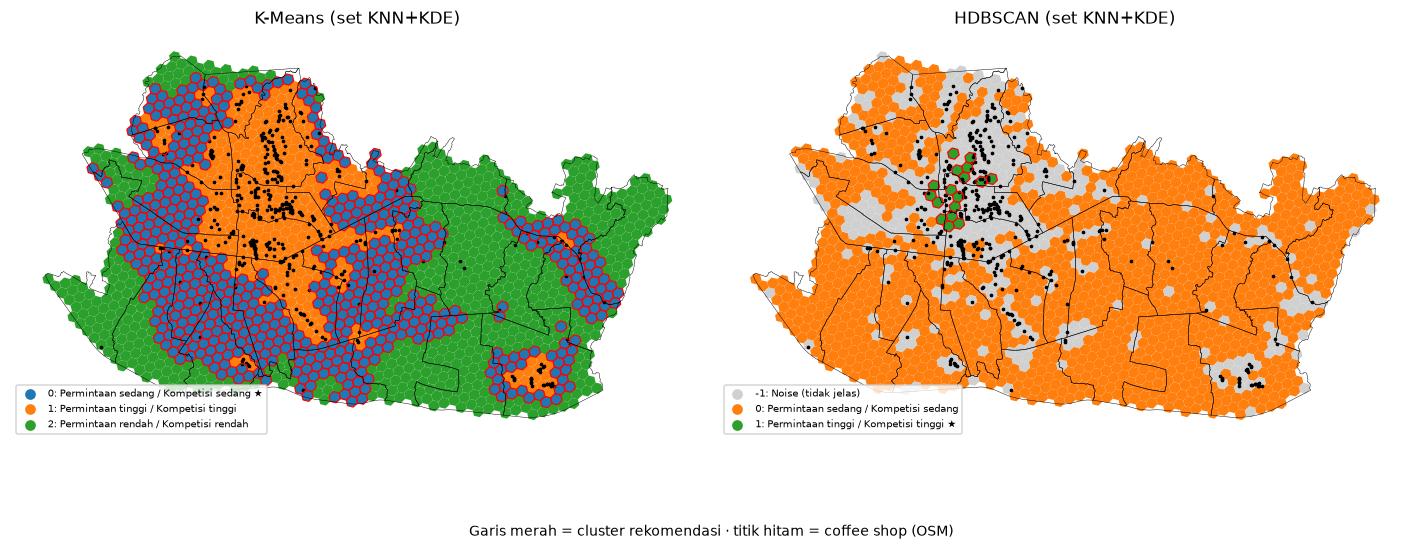

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, alg in zip(ax, ("K-Means", "HDBSCAN")):
    p, rek = PROFIL[alg]
    g = grid.assign(cluster=LABEL[(UTAMA, alg)])
    cmap = plt.get_cmap("tab10")
    warna = {c: ("#d0d0d0" if c == -1 else cmap(i % 10)) for i, c in enumerate(sorted(g.cluster.unique()))}
    g.plot(color=g.cluster.map(warna), ax=a, linewidth=0)
    g[g.cluster == rek].boundary.plot(ax=a, color="red", lw=.8)
    kecamatan_m.boundary.plot(ax=a, color="k", lw=.3)
    komp_kota.plot(ax=a, color="k", markersize=2)
    for c, w in warna.items():
        a.scatter([], [], color=w, label=f"{c}: {p.loc[c, 'nama']}" + (" ★" if c == rek else ""))
    a.legend(loc="lower left", fontsize=6.5, frameon=True)
    a.set_title(f"{alg} (set {UTAMA})")
    a.set_axis_off()
fig.suptitle("Garis merah = cluster rekomendasi · titik hitam = coffee shop (OSM)", y=.04, fontsize=9)
plt.tight_layout(); plt.savefig("peta_kmeans_vs_hdbscan.png", dpi=160); plt.show()

### 10b. Peta interaktif (folium) → `peta_cluster.html`
Buka file HTML di browser. Layer K-Means/HDBSCAN bisa dinyalakan/dimatikan; klik sel untuk melihat nilai fiturnya.

In [22]:
import folium
g4326 = grid.assign(km=LABEL[(UTAMA, "K-Means")], hdb=LABEL[(UTAMA, "HDBSCAN")]).to_crs(4326)
m = folium.Map(location=[-6.917, 107.619], zoom_start=12, tiles="cartodbpositron")
pal = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
for col, alg in (("km", "K-Means"), ("hdb", "HDBSCAN")):
    p, rek = PROFIL[alg]
    gg = g4326[["h3", "kecamatan", col, "d_komp1", "kde_permintaan", "kde_kompetitor", "skor_peluang", "geometry"]].copy()
    gg["cluster"] = gg[col].astype(int); gg["tipe"] = gg.cluster.map(p.nama)
    gg = gg.drop(columns=col).round(1)
    folium.GeoJson(gg, name=f"{alg} (★ = cluster {rek})", show=(alg == "K-Means"),
        style_function=lambda f, rek=rek: {
            "fillColor": "#cccccc" if f["properties"]["cluster"] == -1 else pal[f["properties"]["cluster"] % 10],
            "color": "red" if f["properties"]["cluster"] == rek else "none",
            "weight": 1.2, "fillOpacity": .55},
        tooltip=folium.GeoJsonTooltip(["cluster", "tipe", "kecamatan", "d_komp1", "kde_permintaan", "kde_kompetitor", "skor_peluang"])
    ).add_to(m)
fg = folium.FeatureGroup("Coffee shop (OSM)")
for _, r in komp_kota.to_crs(4326).iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=2, color="black", fill=True, tooltip=r["name"]).add_to(fg)
fg.add_to(m); folium.LayerControl(collapsed=False).add_to(m)
m.save("peta_cluster.html"); print("Disimpan: peta_cluster.html")

Disimpan: peta_cluster.html


## 11. Fungsi rekomendasi: input 1 titik → area rekomendasi
Di sinilah **KNN dipakai lagi untuk aplikasi**: dari titik yang dipilih pengguna, cari sel-sel terdekat (BallTree, jarak haversine) yang termasuk cluster rekomendasi, lalu urutkan berdasarkan skor peluang.
Di aplikasi Streamlit nanti, `lat, lon` didapat dari klik di peta (`streamlit-folium`).

In [23]:
lat_c = np.array([h3.cell_to_latlng(c)[0] for c in grid.h3]); lon_c = np.array([h3.cell_to_latlng(c)[1] for c in grid.h3])
TREE = BallTree(np.radians(np.c_[lat_c, lon_c]), metric="haversine")

def rekomendasi(lat, lon, algoritma="K-Means", radius_km=2.0, top_n=5):
    p, rek = PROFIL[algoritma]; lab = LABEL[(UTAMA, algoritma)]
    sel = h3.latlng_to_cell(lat, lon, H3_RES)
    if sel not in idx_of:
        return "Titik berada di luar Kota Bandung."
    i = idx_of[sel]; c = lab[i]
    print(f"Titik ({lat:.5f}, {lon:.5f}) → sel {sel}, Kec. {grid.kecamatan[i]}")
    print(f"  Cluster {c}: {p.loc[c, 'nama']}" + ("  ★ termasuk cluster rekomendasi" if c == rek else ""))
    print(f"  Coffee shop terdekat: {grid.d_komp1[i]:.0f} m | POI permintaan: {grid.kde_permintaan[i]:.0f}/km² | skor peluang: {grid.skor_peluang[i]:.2f}")
    idx, dist = TREE.query_radius(np.radians([[lat, lon]]), r=radius_km / 6371.0, return_distance=True)
    kand = pd.DataFrame({"i": idx[0], "jarak_m": dist[0] * 6371000})
    kand = kand[lab[kand.i] == rek]
    kand = kand.assign(skor_peluang=grid.skor_peluang.values[kand.i], lat=lat_c[kand.i], lon=lon_c[kand.i],
                       kecamatan=grid.kecamatan.values[kand.i], d_komp1_m=grid.d_komp1.values[kand.i],
                       poi_per_km2=grid.kde_permintaan.values[kand.i])
    if kand.empty:
        return f"Tidak ada sel cluster rekomendasi dalam radius {radius_km} km."
    return kand.sort_values("skor_peluang", ascending=False).head(top_n).drop(columns="i").round(4)

# Contoh: titik di sekitar kampus ITB (Jl. Ganesha)
rekomendasi(-6.8915, 107.6107)

Titik (-6.89150, 107.61070) → sel 898c16b6d2bffff, Kec. Coblong
  Cluster 1: Permintaan tinggi / Kompetisi tinggi
  Coffee shop terdekat: 89 m | POI permintaan: 110/km² | skor peluang: -0.29


,jarak_m,skor_peluang,lat,lon,kecamatan,d_komp1_m,poi_per_km2
74,1670.0651,-0.0143,-6.8799,107.6011,Cidadap,234.6668,47.6505
12,1841.8301,-0.3445,-6.8807,107.5980,Sukajadi,412.5876,49.6229
1,1820.4022,-1.2449,-6.8928,107.5943,Sukajadi,317.5035,52.1250
7,1999.6419,-1.2873,-6.8846,107.5940,Sukajadi,200.9876,43.5874
6,1998.0497,-1.5577,-6.8876,107.5930,Sukajadi,334.5249,43.5971


In [24]:
# Contoh lain: sekitar Alun-alun Bandung, pakai hasil HDBSCAN
rekomendasi(-6.9218, 107.6070, algoritma="HDBSCAN", radius_km=2)

Titik (-6.92180, 107.60700) → sel 898c1479ea3ffff, Kec. Regol
  Cluster -1: Noise (tidak jelas)
  Coffee shop terdekat: 204 m | POI permintaan: 118/km² | skor peluang: -1.20


,jarak_m,skor_peluang,lat,lon,kecamatan,d_komp1_m,poi_per_km2
96,1801.7973,-0.1657,-6.9056,107.6073,Sumur Bandung,228.0663,106.6534
106,1469.0883,-0.1812,-6.9086,107.6063,Sumur Bandung,185.1348,101.8385
95,1433.0341,-0.1847,-6.9095,107.6032,Sumur Bandung,288.1948,92.6623
103,1240.3586,-0.4311,-6.9107,107.6085,Sumur Bandung,255.3206,110.1499
102,1146.8027,-0.4685,-6.9116,107.6054,Sumur Bandung,307.1065,100.4935


## 12. Simpan hasil

In [25]:
out = grid.assign(cluster_kmeans=LABEL[(UTAMA, "K-Means")], cluster_hdbscan=LABEL[(UTAMA, "HDBSCAN")]).to_crs(4326)
out.drop(columns=["x", "y"]).to_file("grid_fitur_cluster.geojson", driver="GeoJSON")
hasil.merge(pd.DataFrame(val), on=["set_fitur", "algoritma"], how="left").to_csv("tabel_evaluasi.csv", index=False)
print("Disimpan: grid_fitur_cluster.geojson, tabel_evaluasi.csv, peta_cluster.html, peta_kmeans_vs_hdbscan.png")

Disimpan: grid_fitur_cluster.geojson, tabel_evaluasi.csv, peta_cluster.html, peta_kmeans_vs_hdbscan.png


## Interpretasi hasil (snapshot OSM dari BBBike, dijalankan Oktober 2026)
*Angka di bawah berasal dari eksekusi notebook ini. Kalau data atau parameter diubah, tulis ulang bagian ini.*

**1. K-Means lebih cocok untuk data grid ini.** Pada set utama (KNN+KDE), K-Means membagi kota menjadi 3 tipe area yang jelas di peta: inti (permintaan & kompetisi tinggi), cincin transisi (sedang/sedang, *cluster rekomendasi*), dan pinggiran (rendah/rendah). Stabilitasnya tinggi (ARI ≈ 0,94), koherensi spasialnya kuat (z ≈ 65), dan pada validasi hold-out AUC ≈ 0,74.

**2. HDBSCAN kesulitan.** Dari 50 konfigurasi, **tidak ada satu pun** yang menghasilkan ≥ 3 cluster dengan noise ≤ 30% pada set utama. Hasil terbaiknya hanya 2 cluster (satu sangat kecil, 17 sel di pusat kota) dengan ±24% noise, stabilitas rendah (ARI ≈ 0,38), dan AUC hold-out ≈ 0,64. Silhouette HDBSCAN tampak lebih tinggi, tetapi itu karena sel yang sulit dibuang sebagai noise. Penyebabnya: fitur sel grid membentuk **gradasi kontinu** dari pusat ke pinggiran, tanpa "celah kepadatan" yang dibutuhkan algoritma berbasis kepadatan.

**3. Ablation KNN vs KDE vs gabungan.** Untuk K-Means, set **KDE saja** memberi silhouette tertinggi (0,30) dan stabilitas tertinggi (0,97); set gabungan tidak memperbaiki metrik internal. Ini konsisten dengan korelasi tinggi antar fitur KNN dan KDE (redundan). Metrik internal saja belum cukup untuk memilih set fitur: validasi hold-out sebaiknya juga dijalankan untuk semua set (ubah `UTAMA` lalu jalankan ulang bagian 8c).

**4. GMM** tidak menemukan jumlah komponen optimal (BIC turun terus sampai 10) dan silhouette-nya paling rendah, sehingga cukup dijadikan pembanding tambahan.

**Implikasi untuk penelitian:**
- Perbandingan K-Means vs HDBSCAN tetap layak dan menghasilkan temuan yang bisa dibahas ("algoritma berbasis kepadatan kurang cocok untuk tipologi area berbasis grid").
- Alternatif agar HDBSCAN lebih adil: (a) jalankan HDBSCAN pada **titik coffee shop** (untuk menemukan kawasan kafe), atau (b) kurangi dimensi dengan PCA / buang fitur redundan dulu.
- Cluster rekomendasi K-Means masih luas (±63 km²), sehingga di aplikasi sel-selnya **diurutkan dengan skor peluang** (fungsi `rekomendasi()`).

## Catatan & langkah berikutnya
- **Kelengkapan OSM**: lakukan cek manual di 1–2 kecamatan dan laporkan % cakupan.
- **Sensitivitas**: ubah `BANDWIDTH_M` (300/500/800), `K_PILOT`, `H3_RES` (8/9), dan lihat apakah kesimpulan K-Means vs HDBSCAN berubah.
- **Validasi temporal**: ambil snapshot OSM lama (mis. lewat ohsome API), lalu cek apakah coffee shop yang baru muncul jatuh di cluster rekomendasi.
- **Fitur tambahan**: kepadatan penduduk (WorldPop), jarak jaringan jalan (osmnx), data Open Data Kota Bandung.
- **Aplikasi**: bungkus fungsi `rekomendasi()` dengan Streamlit + `streamlit-folium` untuk input klik peta.